# 01 · Data quality

Checks that the daily dataset built in Phase 1 is complete and trustworthy before any model sees it. Rebuild the data with `uv run python scripts/download_data.py` and `uv run python scripts/build_dataset.py`, then run this notebook top to bottom.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fxml.config import load_config
from fxml import viz

cfg = load_config()
viz.apply_style()
colors = viz.pair_colors(cfg.pairs)
panel = pd.read_parquet(cfg.paths.processed / "daily_bars.parquet")
macro = pd.read_parquet(cfg.paths.processed / "macro.parquet")
rates = pd.read_parquet(cfg.paths.processed / "policy_rates.parquet")
pairs = list(cfg.pairs)
pd.set_option("display.precision", 4)

## Coverage

For each symbol:
- how many trading days its data starts after or ends before the configured period;
- the share of expected trading days present (weekdays except 25 December and 1 January);
- how many sessions are thin (under half a day of data) or partial (an hour or more with no data).

In [2]:
from fxml.data.quality import coverage_report
coverage_report(panel, cfg.start, cfg.end)

,first,last,start_gap_days,end_gap_days,coverage_pct,missing,thin_days,partial_days,median_minutes
AUDUSD,2006-01-03,2026-10-23,1,5,100.0000,0,30,125,1428.0
EURUSD,2006-01-03,2026-10-23,1,5,100.0000,0,21,100,1433.0
GBPUSD,2006-01-03,2026-10-23,1,5,100.0000,0,22,113,1433.0
NZDUSD,2006-01-03,2026-10-23,1,5,100.0000,0,41,136,1426.0
SPXUSD,2010-11-15,2026-10-23,1262,5,99.4683,22,143,374,1215.0
USDCAD,2006-01-03,2026-10-23,1,5,100.0000,0,38,135,1421.0
USDCHF,2006-01-03,2026-10-23,1,5,99.9815,1,22,113,1426.0
USDJPY,2006-01-03,2026-10-23,1,5,100.0000,0,20,105,1431.0
XAUUSD,2009-03-16,2026-10-23,829,5,99.6062,18,15,256,1379.0


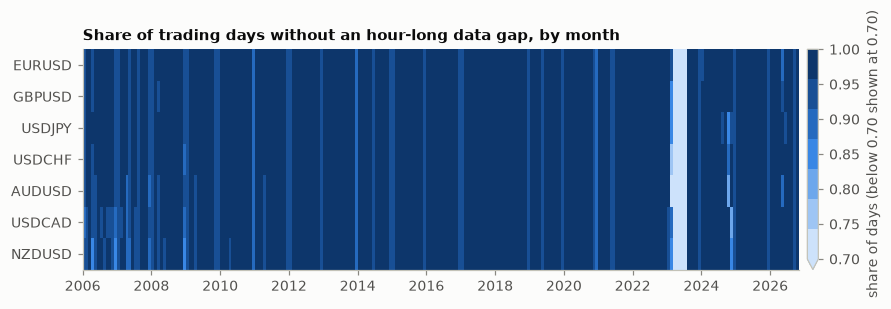

In [3]:
# Share of each month's trading days without a gap of an hour or more, per pair
full = (~panel["partial"]).rename("full").reset_index()
full = full[full["symbol"].isin(pairs)]
monthly = full.groupby(["symbol", pd.Grouper(key="date", freq="MS")])["full"].mean().unstack(0)[pairs]

month_edges = monthly.index.append(pd.DatetimeIndex([monthly.index[-1] + pd.offsets.MonthBegin()]))
fig, ax = plt.subplots(figsize=(10, 2.6))
mesh = ax.pcolormesh(month_edges, np.arange(len(pairs) + 1), monthly.T.values,
                     cmap=plt.matplotlib.colors.ListedColormap(viz.SEQUENTIAL_BLUE),
                     vmin=0.7, vmax=1.0, shading="flat")
ax.set_yticks(np.arange(len(pairs)) + 0.5, pairs)
ax.invert_yaxis()
ax.grid(False)
ax.set_title("Share of trading days without an hour-long data gap, by month")
fig.colorbar(mesh, ax=ax, pad=0.01, extend="min", label="share of days (below 0.70 shown at 0.70)")
viz.save(fig, "data_session_coverage")

## Agreement with an independent source

The Federal Reserve's H.10 release publishes noon New York rates. We take our own price at 12:00 New York from the 5-minute bars, so daily returns of the two should be almost identical. The match is also shown separately for winter, summer and the weeks when US and EU daylight saving disagree. That split exposed HistData's clock: New York time until 2018, then EET minus 7 hours.

In [4]:
from fxml.data.quality import h10_check
h10_check(panel, macro, cfg.pairs)

,days,return_corr,return_corr_winter,return_corr_summer,return_corr_clock_gap,clock_gap_days,mean_abs_level_gap_pct
EURUSD,5156,0.9980,0.9996,0.9972,0.9997,345,0.0095
GBPUSD,5156,0.9977,0.9991,0.9971,0.9954,346,0.0147
USDJPY,5152,0.9973,0.9979,0.9970,0.9927,346,0.0103
USDCHF,5154,0.9983,0.9997,0.9973,0.9955,347,0.0119
AUDUSD,5155,0.9986,0.9988,0.9985,0.9992,344,0.0209
USDCAD,5144,0.9979,0.9980,0.9978,0.9997,343,0.0134
NZDUSD,5151,0.9984,0.9985,0.9984,0.9990,344,0.0297


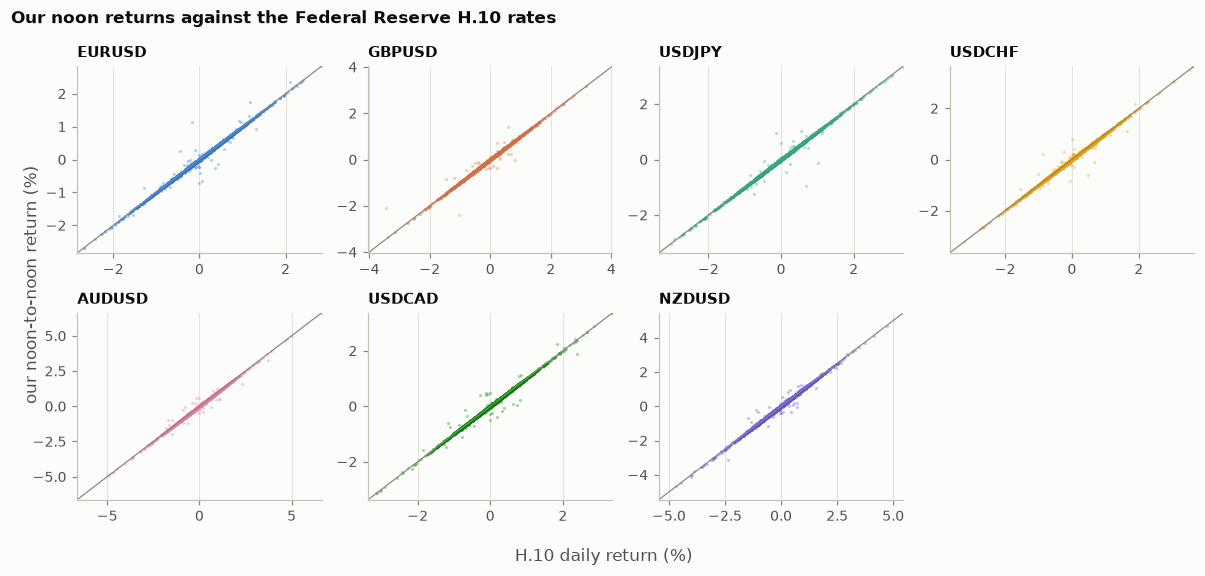

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.2), sharex=False)
for ax, pair in zip(axes.flat, pairs):
    both = pd.concat({"ours": panel.xs(pair, level="symbol")["noon"],
                      "fed": macro[f"h10_{pair}"]}, axis=1, sort=True).dropna()
    r = 100 * np.log(both).diff().dropna()
    ax.scatter(r["fed"], r["ours"], s=4, color=colors[pair], alpha=0.35, linewidths=0)
    lim = np.nanpercentile(np.abs(r.values), 99.9)
    ax.plot([-lim, lim], [-lim, lim], color=viz.INK_MUTED, lw=0.8)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=pair)
    ax.grid(axis="both")
axes.flat[-1].axis("off")
fig.supxlabel("H.10 daily return (%)", color=viz.INK_SECONDARY)
fig.supylabel("our noon-to-noon return (%)", color=viz.INK_SECONDARY)
fig.suptitle("Our noon returns against the Federal Reserve H.10 rates", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "data_h10_agreement")

## Largest daily moves

The biggest close-to-close moves should line up with real events (for example USD/CHF on 15 January 2015). Anything that does not is a data error to investigate.

In [6]:
from fxml.data.quality import largest_moves
largest_moves(panel)

,date,symbol,ret,abs_ret_pct
0,2008-10-13,AUDUSD,0.0826,8.2586
1,2008-10-24,AUDUSD,-0.0737,7.3718
2,2008-10-06,AUDUSD,-0.0691,6.9113
3,2008-10-28,AUDUSD,0.0642,6.4216
4,2008-10-10,AUDUSD,-0.0615,6.1474
5,2009-03-18,EURUSD,0.0345,3.4503
6,2015-12-03,EURUSD,0.0302,3.0155
7,2008-12-17,EURUSD,0.0288,2.8843
8,2008-11-24,EURUSD,0.0285,2.8497
9,2008-11-04,EURUSD,0.0264,2.6379


## Policy rates and market context

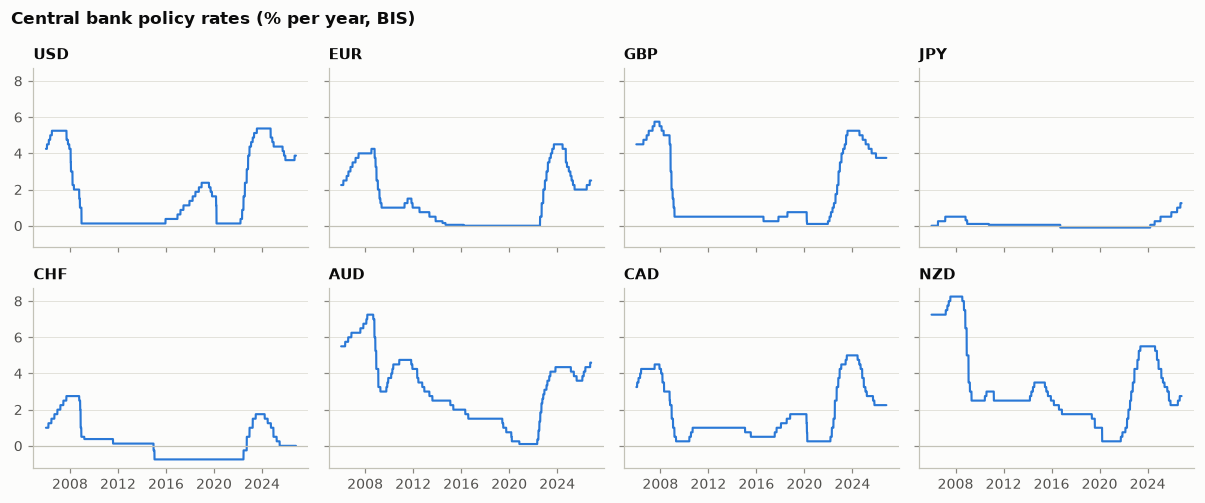

In [7]:
currencies = list(rates.columns)
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, ccy in zip(axes.flat, currencies):
    ax.plot(rates.index, rates[ccy], color=viz.CATEGORICAL[0])
    ax.axhline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(ccy)
fig.suptitle("Central bank policy rates (% per year, BIS)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "data_policy_rates")

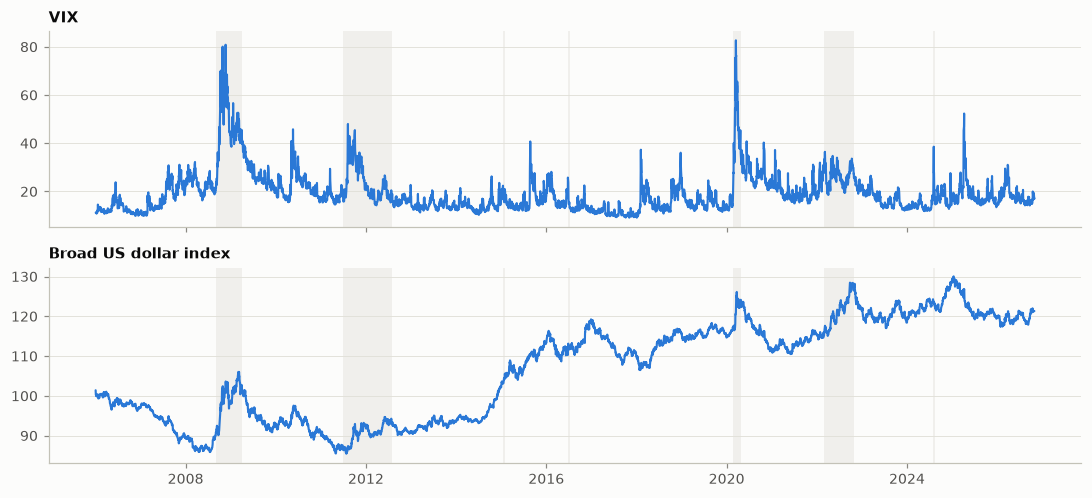

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax, (col, title) in zip(axes, [("vix", "VIX"), ("broad_dollar", "Broad US dollar index")]):
    viz.shade_stress(ax)
    ax.plot(macro.index, macro[col].ffill(), color=viz.CATEGORICAL[0])
    ax.set_title(title)
fig.tight_layout()
viz.save(fig, "data_market_context")

## Findings

- **Coverage.** Six of the seven pairs cover 100% of expected trading days from January 2006; USD/CHF misses a single day. Gold (99.6%) and the S&P 500 (99.5%) miss some US exchange holidays. Every series ends on 23 October 2026, five trading days before the configured end, because HistData publishes the current month in parts. Re-running the download fetches the rest.
- **Data gaps.** Most years have 1–3 sessions with an hour or more without data, nearly all holidays. The exception is March–July 2023, when HistData has multi-hour gaps on 61–79 days per pair. These sessions are flagged `partial`. Realized variance still counts the move across a gap, but those days deserve care in modelling.
- **Clock.** HistData's documentation is wrong:
  - until 2018, its timestamps are New York time;
  - from 2019, they are EET minus 7 hours, so they follow EU daylight-saving dates.

  Read this way, our noon returns match the Federal Reserve's H.10 noon rates at 0.997–0.999 overall. The match is at least 0.993 in winter, in summer and in the weeks when the US and EU clocks differ, and the average price gap is 1–3 pips. A fresh download in a clean clone reproduced every 5-minute bar exactly.
- **Bad ticks.** One impossible wick was removed: NZD/USD on 23 December 2008 shows a high of 2.17 against a price of 0.57. Every other extreme is under 3% and lines up with a real event.
- **Largest moves** match documented episodes:
  - USD/CHF −19.5% on 15 January 2015 and +9% on 6 September 2011, when the franc cap was removed and introduced;
  - GBP/USD −8.8% after the Brexit vote;
  - the October 2008 collapse of the Australian and New Zealand dollars;
  - March 2020.
- **Policy rates** are complete for all eight currencies. The yen rate is carried back at 0% for January–March 2006, before the BIS daily series begins.
